# CMP6202 – Notebook 02: Splitting and exploratory data analysis

**Project:** Multi-class Classification for Cloud Network Intrusion Detection on AWS Using CSE-CIC-IDS2018

This notebook covers report sections **2.1–2.4**. It loads the de-duplicated 75,000-flow sample produced by notebook 01,
splits it once into training and test sets, proves that the split is leakage-free, and then explores the **training
set only**. Every statistic shown here (variances, correlations, mutual information, outlier fences) is computed without
the test set, so none of my modelling decisions can be shaped by data the models will be evaluated on.

Each analysis ends with a copy-ready paragraph saved under `reports/text/`; every number in those paragraphs is
computed by the code above it.

In [1]:
import json

import numpy as np
import pandas as pd
from IPython.display import display

from nids import config, data, eda, features, plotting

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
plotting.apply_style()
for folder in (config.FIGURES_DIR, config.TABLES_DIR, config.TEXT_DIR):
    folder.mkdir(parents=True, exist_ok=True)


def save_text(name: str, text: str) -> None:
    # I save every copy-ready paragraph so the report quotes the code's numbers. Single line breaks
    # inside a paragraph are joined so the text pastes into Word as clean paragraphs.
    paragraphs = [" ".join(block.split()) for block in text.strip().split("\n\n")]
    clean = "\n\n".join(paragraphs)
    (config.TEXT_DIR / f"{name}.txt").write_text(clean + "\n")
    print(clean, f"\n\n[{len(clean.split())} words → reports/text/{name}.txt]")


sample = data.load_sample()
manifest = json.loads(config.MANIFEST_JSON.read_text())
assert manifest["sample_sha256"] == data.sha256_of(config.SAMPLE_PARQUET), "sample differs from manifest"
print(f"Sample: {sample.shape[0]:,} flows × {sample.shape[1]} columns (SHA-256 matches the manifest)")

Sample: 75,000 flows × 80 columns (SHA-256 matches the manifest)


# 2 Exploratory Data Analysis

## 2.1 Question(s) identification

My exploration is organised around three questions. Each one feeds a concrete modelling decision.

| | Question | Decision it informs |
|---|---|---|
| **Q1** | How severe is the class imbalance once duplicate flows are removed? | Evaluation metrics; whether and how to resample |
| **Q2** | Which flow statistics separate brute-force traffic from benign traffic *without* the destination port or time, and do the two attacks differ from each other? | Feature set; shortcut risks; which models are appropriate |
| **Q3** | How skewed, outlier-prone and redundant are the numeric features? | Scaling, outlier handling, regularisation |

**Working hypothesis for Q2.** A brute-force login attempt is a short, repetitive exchange that carries little or no
application payload, so packet-length and header-length features should separate attacks from benign traffic, and
the two attacks should look internally uniform because each is generated by a single tool.

## 2.2 Splitting the dataset

I split once, before any exploration, with an 80/20 ratio stratified by `Label` and a fixed seed. Stratification is
essential here: only 46 unique FTP-BruteForce flows exist, and a purely random split could leave the test set with
almost none of them. The 80/20 ratio leaves 60,000 flows for 5-fold cross-validation and 15,000 for a test set that is
used exactly once, in the final evaluation.

In [2]:
split = data.split_sample(sample)
leakage = data.assert_no_leakage(split)
data.save_split(split)

partition_counts = pd.DataFrame({
    "train": split.y_train.value_counts(),
    "test": split.y_test.value_counts(),
}).reindex(plotting.CLASS_ORDER)
partition_counts["train %"] = partition_counts["train"] / partition_counts["train"].sum() * 100
partition_counts["test %"] = partition_counts["test"] / partition_counts["test"].sum() * 100
partition_counts.loc["Total"] = partition_counts.sum()
display(partition_counts.round(2))
partition_counts.round(2).to_csv(config.TABLES_DIR / "2_2_split_counts.csv")
print("Leakage check:", leakage)

,train,test,train %,test %
Label,,,,
Benign,50857,12715,84.76,84.77
FTP-BruteForce,37,9,0.06,0.06
SSH-Bruteforce,9106,2276,15.18,15.17
Total,60000,15000,100.00,100.00


Leakage check: {'train_rows': 60000, 'test_rows': 15000, 'unique_train_vectors': 60000, 'unique_test_vectors': 15000, 'shared_vectors': 0}


**Leakage check.** `assert_no_leakage` hashes the feature vector of every flow (ignoring `Timestamp` and `Dst Port`,
the same space used for de-duplication) and raises an error if any vector occurs in both partitions or twice within
one. The test suite also includes a deliberately leaky split to show that the check does catch a copied flow.

**Base preprocessing pipeline.** Everything that learns from data sits inside one pipeline so that cross-validation
refits it on each training fold: `Protocol` is one-hot encoded, constant columns are dropped, the numeric features are
standardised, and in step 5 SMOTE is inserted between preprocessing and the classifier. Below I fit only the
preprocessing part on the training set to confirm the resulting feature space.

In [3]:
preprocessor = features.build_preprocessor(split.X_train)
transformed = preprocessor.fit_transform(split.X_train)
drop_step = preprocessor.named_transformers_["numeric"].named_steps["drop_constant"]
numeric_in = preprocessor.named_transformers_["numeric"].feature_names_in_
dropped_constant = [c for c, keep in zip(numeric_in, drop_step.get_support()) if not keep]

print(f"Model input: {transformed.shape[1]} features "
      f"({len(preprocessor.named_transformers_['protocol'].get_feature_names_out())} one-hot Protocol + "
      f"{len(numeric_in) - len(dropped_constant)} numeric)")
print(f"Excluded before modelling: {list(config.MODEL_EXCLUDED_COLS)}")
print(f"Constant in the training set, dropped by VarianceThreshold: {dropped_constant}")
preprocessor

Model input: 69 features (3 one-hot Protocol + 66 numeric)
Excluded before modelling: ['Timestamp', 'Dst Port']
Constant in the training set, dropped by VarianceThreshold: ['Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'CWE Flag Count', 'Fwd Byts/b Avg', 'Fwd Pkts/b Avg', 'Fwd Blk Rate Avg', 'Bwd Byts/b Avg', 'Bwd Pkts/b Avg', 'Bwd Blk Rate Avg']


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('protocol', ...), ('numeric', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transfo

In [4]:
counts = split.y_train.value_counts()
ftp_train, ftp_test = counts["FTP-BruteForce"], split.y_test.value_counts()["FTP-BruteForce"]
save_text("2_2_splitting", f'''
I split the 75,000-flow sample into a training set ({len(split.X_train):,} flows, 80%) and a test set
({len(split.X_test):,} flows, 20%) using a stratified split on Label with a fixed seed (random_state = {config.SEED}).
Stratification keeps the class proportions identical in both partitions (Benign {partition_counts.loc['Benign', 'train %']:.2f}%,
SSH-Bruteforce {partition_counts.loc['SSH-Bruteforce', 'train %']:.2f}%, FTP-BruteForce {partition_counts.loc['FTP-BruteForce', 'train %']:.2f}%),
which matters most for FTP-BruteForce: only 46 unique FTP flows survived de-duplication, so the training set holds
{ftp_train} and the test set {ftp_test}. Because duplicates were removed before splitting, I could verify that no feature
vector appears in both partitions ({leakage['shared_vectors']} shared vectors, checked by hashing every flow). Every step that
learns from data (exploration, constant-feature removal, scaling, SMOTE and hyper-parameter tuning) uses the training
set only, inside 5-fold stratified cross-validation; the test set is used once, for the final evaluation. With
{ftp_train} training flows, each fold trains on about {round(ftp_train * 0.8)} FTP flows and validates on about {round(ftp_train * 0.2)},
so per-class scores for FTP-BruteForce will have high variance, and I report their spread across folds.
''')

I split the 75,000-flow sample into a training set (60,000 flows, 80%) and a test set (15,000 flows, 20%) using a stratified split on Label with a fixed seed (random_state = 42). Stratification keeps the class proportions identical in both partitions (Benign 84.76%, SSH-Bruteforce 15.18%, FTP-BruteForce 0.06%), which matters most for FTP-BruteForce: only 46 unique FTP flows survived de-duplication, so the training set holds 37 and the test set 9. Because duplicates were removed before splitting, I could verify that no feature vector appears in both partitions (0 shared vectors, checked by hashing every flow). Every step that learns from data (exploration, constant-feature removal, scaling, SMOTE and hyper-parameter tuning) uses the training set only, inside 5-fold stratified cross-validation; the test set is used once, for the final evaluation. With 37 training flows, each fold trains on about 30 FTP flows and validates on about 7, so per-class scores for FTP-BruteForce will have high 

## 2.3 Exploratory Data Analysis process and results

### 2.3.1 Class imbalance (Q1)

,flows,percent
Label,,
Benign,50857,84.762
FTP-BruteForce,37,0.062
SSH-Bruteforce,9106,15.177


Benign : FTP-BruteForce = 1,375 : 1;  share of raw FTP rows that were repeats: 99.98%


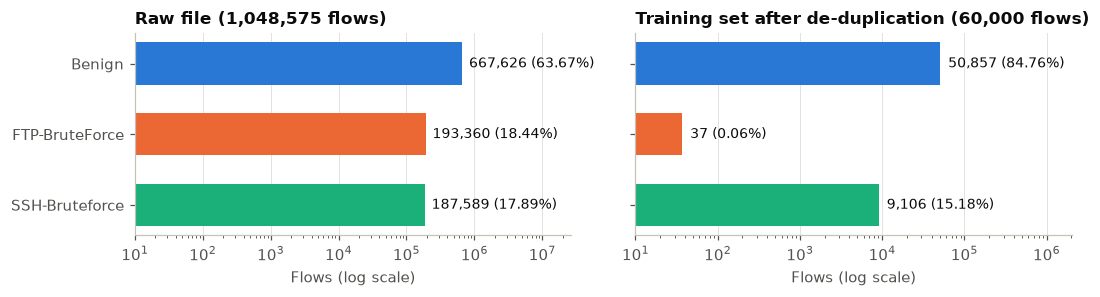

In [5]:
raw_counts = pd.Series(manifest["stage_counts"]["1. Raw file"]).drop("Total")
fig = plotting.plot_class_distribution(raw_counts, split.y_train.value_counts())
plotting.save_figure(fig, "2_3_1_class_distribution")

train_counts = eda.class_counts(split.y_train)
display(train_counts.round(3))
imbalance_ratio = train_counts.loc["Benign", "flows"] / train_counts.loc["FTP-BruteForce", "flows"]
ftp_repeat_share = 1 - manifest["stage_counts"]["7. Unique flows (sampling frame)"]["FTP-BruteForce"] / raw_counts["FTP-BruteForce"]
print(f"Benign : FTP-BruteForce = {imbalance_ratio:,.0f} : 1;  share of raw FTP rows that were repeats: {ftp_repeat_share:.2%}")

### 2.3.2 Feature scales and redundancy (Q3)

On the raw scale a variance ranking would only reproduce the units (bytes per second dwarf flag counts), so I rank the
66 non-constant numeric features by variance **after** a symmetric log transform, `sign(x)·log1p(|x|)`. I use the
symmetric form instead of plain `log1p` because the window columns contain `-1`, for which `log1p` is −∞. The heatmap
shows Pearson correlations of the 20 highest-variance features on the same transformed scale, ordered by hierarchical
clustering so that redundant groups form blocks.

,feature_a,feature_b,r
64,Idle Max,Idle Mean,1.0000
44,Idle Min,Idle Mean,0.9999
43,Idle Min,Idle Max,0.9998
295,Bwd IAT Tot,Bwd IAT Max,0.9979
211,Fwd IAT Tot,Fwd IAT Max,0.9954
275,Bwd IAT Mean,Bwd IAT Max,0.9948
274,Bwd IAT Mean,Bwd IAT Tot,0.9937
191,Fwd IAT Mean,Fwd IAT Max,0.9925
190,Fwd IAT Mean,Fwd IAT Tot,0.9858


66 non-constant numeric features; max Flow Duration 119,999,221; max Flow Byts/s 394,000,000
Pkt Len Var == Pkt Len Std² on every training flow: True


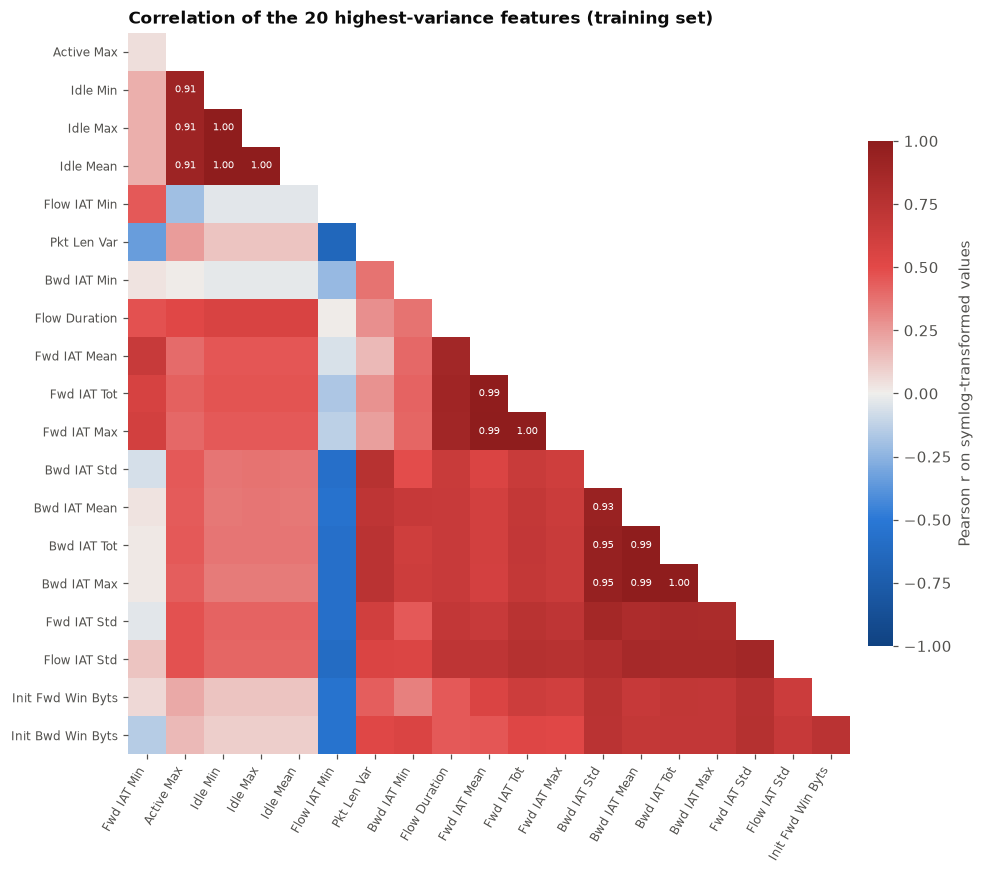

In [6]:
X_numeric = eda.numeric_model_features(split.X_train)
variance = eda.variance_ranking(X_numeric)
top_variance = variance.head(20).index.tolist()
corr = eda.correlation_matrix(X_numeric, top_variance)
redundant = eda.highly_correlated_pairs(corr, threshold=0.95)

fig = plotting.plot_correlation_heatmap(corr)
plotting.save_figure(fig, "2_3_2_correlation_heatmap")

variance.head(20).round(2).rename("variance (symlog)").to_csv(config.TABLES_DIR / "2_3_2_variance_ranking.csv")
redundant.round(4).to_csv(config.TABLES_DIR / "2_3_2_redundant_pairs.csv", index=False)
display(redundant.round(4))
pkt_var_is_std_squared = np.allclose(split.X_train["Pkt Len Var"], split.X_train["Pkt Len Std"] ** 2, rtol=1e-6)
print(f"{X_numeric.shape[1]} non-constant numeric features; max Flow Duration {X_numeric['Flow Duration'].max():,.0f}; "
      f"max Flow Byts/s {X_numeric['Flow Byts/s'].max():,.0f}")
print(f"Pkt Len Var == Pkt Len Std² on every training flow: {pkt_var_is_std_squared}")

### 2.3.3 Discriminative features and outliers (Q2, Q3)

To find the features that carry the most information about the class I estimate the **mutual information** (MI)
between each feature and the label on the training set. Unlike an ANOVA F-test, MI does not assume normally distributed
features and captures the threshold-like separations typical of attack traffic. MI can never exceed the entropy of the
label, H(Y), so I report it as a share of H(Y). Because many top features carry the same information, the box plots
show the six best-ranked features that are not strongly correlated (|r| < 0.9) with one already shown.

,MI as % of H(Y)
Fwd Pkt Len Max,98.8
Init Bwd Win Byts,98.8
Bwd Pkt Len Max,98.7
Init Fwd Win Byts,98.6
Fwd Header Len,98.6
Bwd Seg Size Avg,98.4
Subflow Bwd Byts,98.4
Bwd Pkt Len Mean,98.3
Bwd Header Len,98.3
TotLen Bwd Pkts,98.3


Label,Benign,FTP-BruteForce,SSH-Bruteforce
Fwd Pkt Len Max,52.0,0.0,640.0
Init Bwd Win Byts,60.0,0.0,230.0
Bwd Pkt Len Max,147.0,0.0,976.0
Init Fwd Win Byts,8192.0,26883.0,26883.0
Fwd Header Len,72.0,40.0,712.0
Bwd Header Len,32.0,20.0,712.0


,Benign (% outliers),FTP-BruteForce (% outliers),SSH-Bruteforce (% outliers)
Fwd Pkt Len Max,1.2,0.0,0.2
Init Bwd Win Byts,22.7,0.0,0.0
Bwd Pkt Len Max,0.0,0.0,0.2
Init Fwd Win Byts,2.9,0.0,0.2
Fwd Header Len,3.7,0.0,6.3
Bwd Header Len,7.3,0.0,0.2


H(Y) = 0.431 nats; features with MI >= 90% of H(Y): 26 of 66
Init Fwd Win Byts == 26,883: {'Benign': 0.065, 'FTP-BruteForce': 100.0, 'SSH-Bruteforce': 99.78}
SSH flows at the modal value: {'Fwd Pkt Len Max': np.float64(99.78036459477268), 'Bwd Pkt Len Max': np.float64(99.78036459477268)};  FTP flows with zero payload: 100%


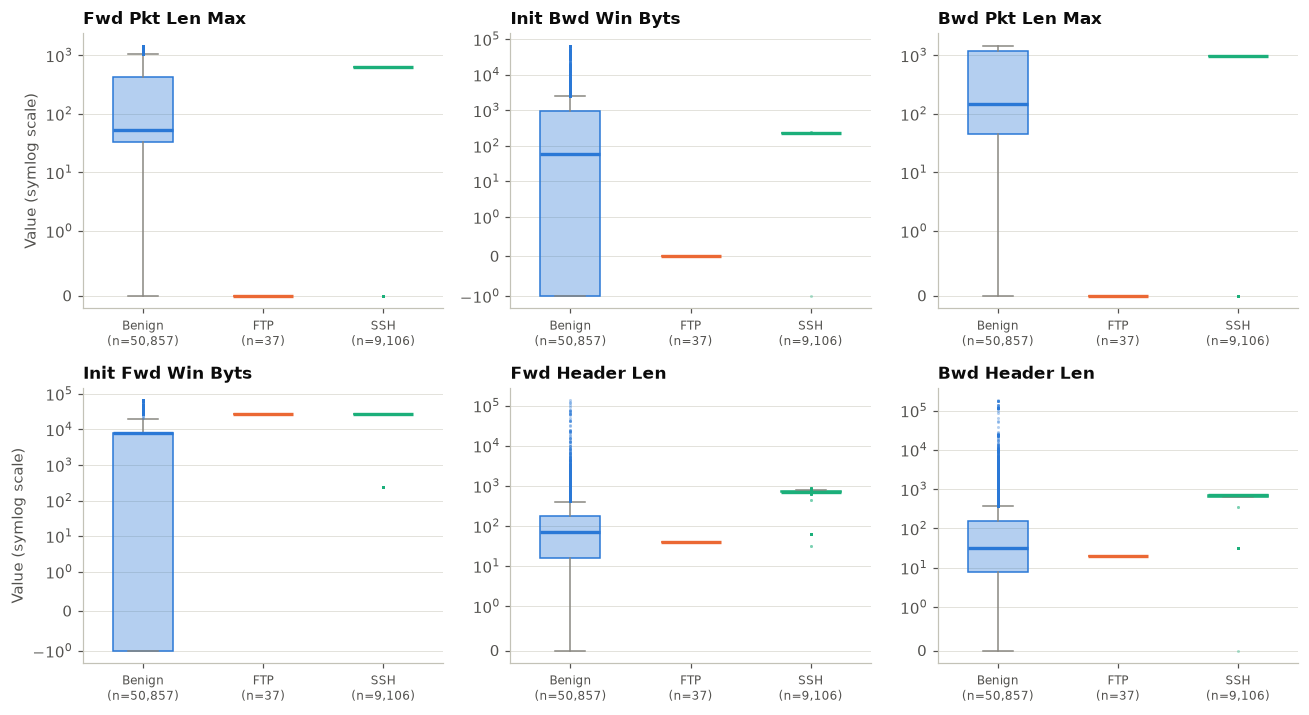

In [7]:
entropy = eda.label_entropy(split.y_train)
mi = eda.mutual_information_ranking(X_numeric, split.y_train)
mi_share = (mi / entropy * 100).rename("MI as % of H(Y)")
display(mi_share.head(15).round(1).to_frame())
mi_share.round(2).to_csv(config.TABLES_DIR / "2_3_3_mutual_information.csv")

box_features = eda.select_diverse(mi, X_numeric, k=6, max_abs_r=0.9)
fig = plotting.plot_class_boxplots(X_numeric, split.y_train, box_features)
plotting.save_figure(fig, "2_3_3_boxplots_by_class")

medians = X_numeric[box_features].groupby(split.y_train, observed=True).median().T
outliers = eda.outlier_share(X_numeric, split.y_train, box_features)
display(medians, outliers.round(1).add_suffix(" (% outliers)"))
outliers.round(2).to_csv(config.TABLES_DIR / "2_3_3_outlier_share.csv")

window_share = split.X_train["Init Fwd Win Byts"].eq(26883).groupby(split.y_train, observed=True).mean() * 100
ssh = split.X_train.loc[split.y_train == "SSH-Bruteforce"]
ssh_uniform = {c: ssh[c].eq(ssh[c].mode()[0]).mean() * 100 for c in ["Fwd Pkt Len Max", "Bwd Pkt Len Max"]}
ftp = split.X_train.loc[split.y_train == "FTP-BruteForce"]
ftp_no_payload = (ftp["TotLen Fwd Pkts"].eq(0) & ftp["TotLen Bwd Pkts"].eq(0)).mean() * 100
print(f"H(Y) = {entropy:.3f} nats; features with MI >= 90% of H(Y): {(mi_share >= 90).sum()} of {len(mi_share)}")
print(f"Init Fwd Win Byts == 26,883: {window_share.round(3).to_dict()}")
print(f"SSH flows at the modal value: {ssh_uniform};  FTP flows with zero payload: {ftp_no_payload:.0f}%")

### 2.3.4 Shortcut check: destination port (Q2)

`Dst Port` is excluded from the main model; this table shows why. CIC created the labels from the attack schedule and
the IPs, ports and protocol of each flow, so the port is part of the labelling procedure rather than a property of the
attack that would generalise to a different service port.

In [8]:
ports = eda.port_profile(split.X_train, split.y_train)
display(ports.round(3))
ports.round(3).to_csv(config.TABLES_DIR / "2_3_4_port_profile.csv", index=False)
benign_ports = split.X_train.loc[split.y_train == "Benign", config.DST_PORT_COL]
benign_on_21, benign_on_22 = benign_ports.eq(21).mean() * 100, benign_ports.eq(22).mean() * 100
print(f"Benign flows on port 21: {benign_on_21:.3f}%, on port 22: {benign_on_22:.3f}%")

,class,dst_port,percent_of_class,distinct_ports_in_class
0,Benign,53,28.368,2544
1,Benign,80,18.731,2544
2,Benign,3389,17.012,2544
3,FTP-BruteForce,21,100.000,1
4,SSH-Bruteforce,22,100.000,1


Benign flows on port 21: 0.006%, on port 22: 0.079%


In [9]:
# One example per redundant group: skip a pair if it reuses a feature already quoted.
examples, used = [], set()
for a, b, r in redundant.itertuples(index=False):
    if a not in used and b not in used:
        examples.append(f"{a} / {b} (r = {r:.3f})")
        used.update({a, b})
top_pairs = "; ".join(examples[:3])
save_text("2_3_eda_results", f'''
Class imbalance (Q1). The raw file looks moderately balanced (FTP-BruteForce {raw_counts['FTP-BruteForce'] / raw_counts.sum():.1%},
SSH-Bruteforce {raw_counts['SSH-Bruteforce'] / raw_counts.sum():.1%}), but {ftp_repeat_share:.2%} of the FTP rows were exact
repeats. After de-duplication the training set is severely imbalanced: Benign {train_counts.loc['Benign', 'percent']:.2f}%,
SSH-Bruteforce {train_counts.loc['SSH-Bruteforce', 'percent']:.2f}% and FTP-BruteForce {train_counts.loc['FTP-BruteForce', 'percent']:.2f}%
({imbalance_ratio:,.0f} benign flows per FTP flow; Figure 2.1). A classifier that never predicts FTP-BruteForce would lose
only {train_counts.loc['FTP-BruteForce', 'percent']:.2f} percentage points of accuracy, so accuracy alone cannot reveal whether the
rare attack is detected.

Scale and redundancy (Q3). The {X_numeric.shape[1]} non-constant numeric features range from binary flag counts to flow
durations of up to {X_numeric['Flow Duration'].max():,.0f} and byte rates of up to {X_numeric['Flow Byts/s'].max():,.0f}. After a
symmetric log transform the highest-variance features are timing statistics (inter-arrival and idle times). Among the 20
features in Figure 2.2, {len(redundant)} of the {len(corr) * (len(corr) - 1) // 2} pairs have |r| ≥ 0.95, for example {top_pairs}; in addition, Pkt Len Var equals
Pkt Len Std squared on every flow.

Discriminative features (Q2). Mutual information with the label shows that many single features almost determine the
class: {(mi_share >= 90).sum()} of {len(mi_share)} features reach at least 90% of the label entropy H(Y) = {entropy:.3f} nats, led by
{mi_share.index[0]} ({mi_share.iloc[0]:.1f}%). Figure 2.3 explains why. FTP-BruteForce flows carry no payload
({ftp_no_payload:.0f}% have zero bytes in both directions), and SSH-Bruteforce flows are almost identical to one another
({ssh_uniform['Fwd Pkt Len Max']:.1f}% share the same maximum forward packet length of
{medians.loc['Fwd Pkt Len Max', 'SSH-Bruteforce']:,.0f} bytes), so their boxes collapse to a line, whereas benign traffic spreads
over several orders of magnitude. Both attacks also share an initial forward TCP window of 26,883 bytes
({window_share['FTP-BruteForce']:.0f}% of FTP and {window_share['SSH-Bruteforce']:.2f}% of SSH flows, against
{window_share['Benign']:.3f}% of benign flows). This value most likely reflects the attacker's operating system rather than
the attack itself, so a model that relies on it may learn to recognise the attacking machine instead of brute-force
behaviour.

Outliers (Q3). Within each class, Tukey's 1.5 × IQR rule flags up to {outliers['Benign'].max():.1f}% of benign flows
(Init Bwd Win Byts) and at most {outliers.drop(columns='Benign').to_numpy().max():.1f}% of attack flows on the six features shown.
These points are legitimate heavy tails of real traffic (large transfers, long sessions), not recording errors, so I keep
them: removing them would make benign traffic look more uniform than it is.

Shortcut check (Q2). In the training set {ports.query("`class` == 'FTP-BruteForce'")['percent_of_class'].iloc[0]:.0f}% of FTP
flows use port 21 and {ports.query("`class` == 'SSH-Bruteforce'")['percent_of_class'].iloc[0]:.0f}% of SSH flows use port 22, against
{benign_on_21:.3f}% and {benign_on_22:.3f}% of benign flows. Because CIC derived the labels from ports and the attack schedule,
the port would let a model reproduce the labelling rule rather than learn traffic behaviour.
''')

Class imbalance (Q1). The raw file looks moderately balanced (FTP-BruteForce 18.4%, SSH-Bruteforce 17.9%), but 99.98% of the FTP rows were exact repeats. After de-duplication the training set is severely imbalanced: Benign 84.76%, SSH-Bruteforce 15.18% and FTP-BruteForce 0.06% (1,375 benign flows per FTP flow; Figure 2.1). A classifier that never predicts FTP-BruteForce would lose only 0.06 percentage points of accuracy, so accuracy alone cannot reveal whether the rare attack is detected.

Scale and redundancy (Q3). The 66 non-constant numeric features range from binary flag counts to flow durations of up to 119,999,221 and byte rates of up to 394,000,000. After a symmetric log transform the highest-variance features are timing statistics (inter-arrival and idle times). Among the 20 features in Figure 2.2, 9 of the 190 pairs have |r| ≥ 0.95, for example Idle Max / Idle Mean (r = 1.000); Bwd IAT Tot / Bwd IAT Max (r = 0.998); Fwd IAT Tot / Fwd IAT Max (r = 0.995); in addition, Pkt Len V

## 2.4 EDA conclusions

In [10]:
save_text("2_4_eda_conclusions", f'''
The exploration answers the three questions and fixes the modelling choices that follow. (Q1) Once duplicates are
removed, the problem is severely imbalanced ({train_counts.loc['FTP-BruteForce', 'percent']:.2f}% FTP-BruteForce), so I evaluate
with macro-averaged F1 and per-class recall alongside weighted F1, and I oversample the minority class with SMOTE inside
the cross-validation pipeline, capped well below the majority size because the class has only {ftp_train} training flows.
(Q2) The hypothesis is supported: payload and header-length features separate both attacks from benign traffic almost
perfectly, so near-perfect scores for Benign and SSH-Bruteforce are expected and are not by themselves evidence of a
good detector. The real tests are the rare FTP class and whether the models depend on shortcuts. I therefore exclude
Dst Port and Timestamp from the main model and run ablations that add Dst Port back and remove the initial window
sizes. (Q3) Features are heavy-tailed and partly redundant ({len(redundant)} of the {len(corr) * (len(corr) - 1) // 2} pairs among the
20 highest-variance features have |r| ≥ 0.95), which
favours tree-based models that are insensitive to scale and correlated inputs, and calls for standardisation and
regularisation for Logistic Regression; I keep outliers because they are genuine traffic.
''')

The exploration answers the three questions and fixes the modelling choices that follow. (Q1) Once duplicates are removed, the problem is severely imbalanced (0.06% FTP-BruteForce), so I evaluate with macro-averaged F1 and per-class recall alongside weighted F1, and I oversample the minority class with SMOTE inside the cross-validation pipeline, capped well below the majority size because the class has only 37 training flows. (Q2) The hypothesis is supported: payload and header-length features separate both attacks from benign traffic almost perfectly, so near-perfect scores for Benign and SSH-Bruteforce are expected and are not by themselves evidence of a good detector. The real tests are the rare FTP class and whether the models depend on shortcuts. I therefore exclude Dst Port and Timestamp from the main model and run ablations that add Dst Port back and remove the initial window sizes. (Q3) Features are heavy-tailed and partly redundant (9 of the 190 pairs among the 20 highest-vari